# Aimf of the notebook

Batch processing of MERSCOPE datasets. OTher datasets are processed in `processing_pipeline-for_batch.ipynb`

# Load functions 

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys

parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../../src/troutpy_reproducibility"))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from batch_running import *

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


##  Batch running of the pipeline

In [141]:
import numpy as np
import pandas as pd
from shapely.geometry import box
import seaborn as sns
import matplotlib.pyplot as plt


def identify_noisy_genes(sdata, plot=True):
    """
    Identify noisy genes based on transcript distribution inside vs outside cells.

    Parameters:
    - sdata: SpatialData object containing 'shapes' and 'transcripts'
    - plot: whether to show a boxplot of total counts stratified by noise level

    Returns:
    - noisy_genes: list of gene names considered noisy
    - transcript_x_cell: DataFrame with gene-wise count and noise annotations
    """
    # Calculate total cell area
    areas = [geom.area for geom in sdata["shapes"]["geometry"]]
    cell_area = np.sum(areas)

    # Define the bounding box of the entire region
    minx, miny, maxx, maxy = sdata["shapes"]["geometry"].total_bounds
    bounding_box = box(minx, miny, maxx, maxy)
    all_area = bounding_box.area
    out_area = all_area - cell_area
    cell2out_ratio = cell_area / out_area

    # Get transcript overlaps and genes
    allgene = sdata["transcripts"][["overlaps_cell", "gene"]].compute()

    # Build gene x overlap crosstab
    transcript_x_cell = pd.crosstab(allgene["gene"], allgene["overlaps_cell"])
    transcript_x_cell["total_counts"] = transcript_x_cell.sum(axis=1)

    # Compute noise level: if normalized inside counts < outside counts
    transcript_x_cell["noise_level"] = transcript_x_cell.get(True, 0) * cell2out_ratio < transcript_x_cell.get(
        False, 0
    )

    # Identify threshold for noisy genes
    noise_genes = transcript_x_cell[transcript_x_cell["noise_level"]]
    noise_threshold = np.median(noise_genes["total_counts"])

    # Annotate genes above and below noise threshold
    transcript_x_cell["above_noise"] = transcript_x_cell["total_counts"] > noise_threshold

    # Plot if requested
    if plot:
        sns.boxplot(data=transcript_x_cell, x="noise_level", y="total_counts")
        plt.yscale("log")
        plt.title("Total Counts vs Noise Level")
        plt.show()

    # Return noisy genes
    noisy_genes = transcript_x_cell.loc[transcript_x_cell["total_counts"] < noise_threshold].index.tolist()

    return noisy_genes, transcript_x_cell


# Ensure `clustering_pipeline` is available in your environment,
# e.g., `from your_module import clustering_pipeline`


def run_troutpy_pipeline(
    inpath,
    data_filename="data.zarr",
    output_filename="data_processed.zarr",
    output_filtered_filename="data_processed_filtered.zarr",
    figures_dir="figures",
    # sainsc parameters
    binsize=3,
    celltype_key="leiden",
    background_filter=0.4,
    gaussian_kernel_key=2.0,
    n_threads=16,
    # extracellular definition
    percentile_threshold=20,
    # aggregation
    square_size_transcripts=10,
    # spatial stats
    n_neighbors=10,
    square_size_variability=20,
    threshold_colocalized=1,
    # exRNA filter
    min_logfoldratio_over_noise=0,
    # source scoring
    lambda_decay=0.1,
    diffusion_distance_key="distance",
):
    """
    Execute a full Troutpy spatial transcriptomics pipeline on the provided dataset.

    Parameters
    ----------
    inpath : str
        Path to the folder containing `data.zarr`.
    data_filename : str, optional
        Name of the input .zarr file (default 'data.zarr').
    output_filename : str, optional
        Name for the first processed output .zarr (default 'data_processed.zarr').
    output_filtered_filename : str, optional
        Name for the filtered output .zarr (default 'data_processed_filtered.zarr').
    figures_dir : str, optional
        Subdirectory under `inpath` to save figures (default 'figures').
    binsize : int, optional
        Bin size for segmentation_free_sainsc (default 3).
    celltype_key : str, optional
        Key for cell clustering labels (default 'leiden').
    background_filter : float, optional
        Background filter threshold for sainsc (default 0.4).
    gaussian_kernel_key : float, optional
        Gaussian kernel sigma for sainsc (default 2.0).
    n_threads : int, optional
        Threads for parallel processing (default 16).
    percentile_threshold : int, optional
        Percentile for extracellular definition (default 20).
    square_size_transcripts : int, optional
        Square size for transcript aggregation (default 10).
    n_neighbors : int, optional
        Number of neighbors for spatial stats (default 10).
    square_size_variability : int, optional
        Square size for spatial variability (default 20).
    threshold_colocalized : int, optional
        Threshold for spatial colocalization (default 1).
    min_logfoldratio_over_noise : float, optional
        Minimum log-fold ratio to filter exRNA (default 0).
    lambda_decay : float, optional
        Lambda decay for source scoring (default 0.1).
    diffusion_distance_key : str, optional
        Key for distance in diffusion assessment (default 'distance').
    """
    # Prepare figure directory
    figures_path = os.path.join(inpath, figures_dir)
    os.makedirs(figures_path, exist_ok=True)

    # Load data
    sdata = sd.read_zarr(os.path.join(inpath, data_filename))

    ### REMOVE LATER
    tran = sdata["transcripts"].compute()
    tran["overlaps_cell"] = tran["cell_id"] != -1
    tran["overlaps_cell"] = tran["cell_id"] != -1
    noisy_genes, transcript_x_cell = identify_noisy_genes(sdata)
    tran["control_probe"] = tran["gene"].isin(noisy_genes)

    sdata["transcripts"] = sd.models.PointsModel.parse(tran)

    # 1. Clustering cells
    clustering_pipeline(sdata)

    # 2. Segmentation-free SAINSc
    troutpy.pp.segmentation_free_sainsc(
        sdata,
        binsize=binsize,
        celltype_key=celltype_key,
        background_filter=background_filter,
        gaussian_kernel_key=gaussian_kernel_key,
        n_threads=n_threads,
    )
    troutpy.pl.histogram(sdata, x="cosine_similarity", hue="overlaps_cell", save=True, figures_path=figures_path)

    # 3. Extracellular definition
    troutpy.pp.define_extracellular(
        sdata, layer="transcripts", method="sainsc", copy=False, percentile_threshold=percentile_threshold
    )

    # 4. Plots: crosstab, pie, heatmap
    troutpy.pl.crosstab(
        sdata,
        yvar="extracellular",
        xvar="overlaps_cell",
        normalize=False,
        cmap="troutpy",
        kind="barh",
        stacked=True,
        save=True,
        figures_path=figures_path,
    )
    troutpy.pl.pie(
        sdata, groupby="match_cell_signature", group_key="overlaps_cell", palette="troutpy", figures_path=figures_path
    )
    troutpy.pl.crosstab(
        sdata,
        xvar="extracellular",
        yvar="overlaps_cell",
        normalize=True,
        cmap="Aquas",
        kind="heatmap",
        stacked=True,
        save=True,
        figures_path=figures_path,
    )

    # 5. Aggregate transcripts
    troutpy.pp.aggregate_extracellular_transcripts(sdata, gene_key="gene", square_size=square_size_transcripts)

    # 6. Spatial statistics
    troutpy.tl.quantify_overexpression(sdata, codeword_key="control_probe", control_codewords=[True], gene_key="gene")
    troutpy.tl.extracellular_enrichment(sdata, gene_key="gene")
    troutpy.tl.spatial_variability(
        sdata, gene_key="gene", n_neighbors=n_neighbors, square_size=square_size_variability
    )
    troutpy.tl.in_out_correlation(sdata, n_neighbors=n_neighbors)
    troutpy.tl.spatial_colocalization(sdata, threshold_colocalized=threshold_colocalized, copy=False)

    # 7. Metric plots
    troutpy.pl.logfoldratio_over_noise(
        sdata, test_method="auto", palette="troutpy", figures_path=figures_path, save=True
    )
    troutpy.pl.metric_scatter(
        sdata,
        x="logfoldratio_over_noise",
        y="extracellular_proportion",
        label_top_n_y=1,
        label_top_n_x=10,
        figures_path=figures_path,
        save=True,
    )
    troutpy.pl.metric_scatter(
        sdata,
        x="in_out_spearmanR",
        y="extracellular_proportion",
        label_top_n_x=10,
        label_bottom_n_x=5,
        figures_path=figures_path,
        save=True,
    )
    troutpy.pl.metric_scatter(
        sdata,
        x="in_out_spearmanR",
        y="moran_I",
        label_top_n_y=5,
        label_bottom_n_y=5,
        figures_path=figures_path,
        save=True,
    )
    troutpy.pl.metric_scatter(
        sdata,
        x="proportion_of_colocalized",
        y="extracellular_proportion",
        label_top_n_x=5,
        label_bottom_n_x=5,
        figures_path=figures_path,
        save=True,
    )

    # Save intermediate processed data
    sdata.write(os.path.join(inpath, output_filename), overwrite=True)

    # 8. Filter exRNA and source scoring
    troutpy.pp.filter_xrna(sdata, min_logfoldratio_over_noise=min_logfoldratio_over_noise, gene_key="gene")
    troutpy.tl.compute_source_score(
        sdata, layer="transcripts", gene_key="gene", lambda_decay=lambda_decay, copy=False, celltype_key=celltype_key
    )

    # 9. Diffusion analysis
    troutpy.tl.assess_diffussion(sdata, gene_key="gene", distance_key=diffusion_distance_key)
    troutpy.pl.diffusion_results(sdata, y_col="-log_ks_pval", y_logscale=True, figures_path=figures_path, save=True)
    troutpy.pl.metric_scatter(
        sdata,
        x="mean_displacement",
        y="extracellular_proportion",
        label_top_n_y=1,
        label_top_n_x=10,
        figures_path=figures_path,
        save=True,
    )
    troutpy.pl.metric_scatter(
        sdata,
        x="mean_displacement",
        y="in_out_spearmanR",
        label_top_n_y=1,
        label_top_n_x=10,
        figures_path=figures_path,
        save=True,
    )

    # Save filtered processed data
    sdata.write(os.path.join(inpath, output_filtered_filename), overwrite=True)
    return sdata

# In here we run MERSCOPE datasets.

In [ ]:
inpath = "/media/sergio/Meninges/troutpy/rois/merscope_hsbrain"

sdata = run_troutpy_pipeline(inpath)

print(sdata)


### The following code includes a bit more in depth analysis of the MERSCOPE dataset and noise probe detections

In [ ]:
inpath = "/media/sergio/Meninges/troutpy/rois/merscope_hsbrain"

saving_path = os.path.join(inpath, "figures")
if not os.path.exists(saving_path):
    os.makedirs(saving_path)
sdata = sd.read_zarr(os.path.join(inpath, "data.zarr"))
meta_path = os.path.join(inpath, "metadata.csv")

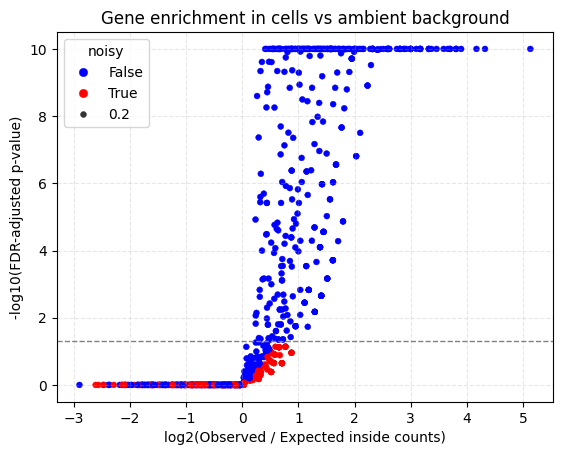

In [14]:
noisy_genes, results_df=identify_noisy_genes(sdata, plot=True, min_inside_count=30, fdr_threshold=0.05)

In [26]:
metadata = pd.read_csv(meta_path)

Proportion of cells retained after filtering: 71.59%


2025-05-30 10:15:09.756414: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-05-30 10:15:09.902701: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1748592909.967814 2488072 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1748592909.986388 2488072 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1748592910.117871 2488072 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

Final adata shape: (1222, 946)


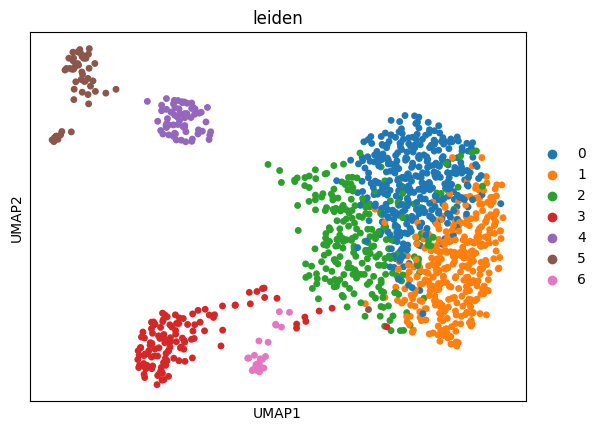

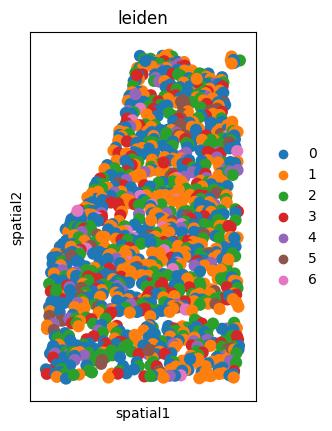

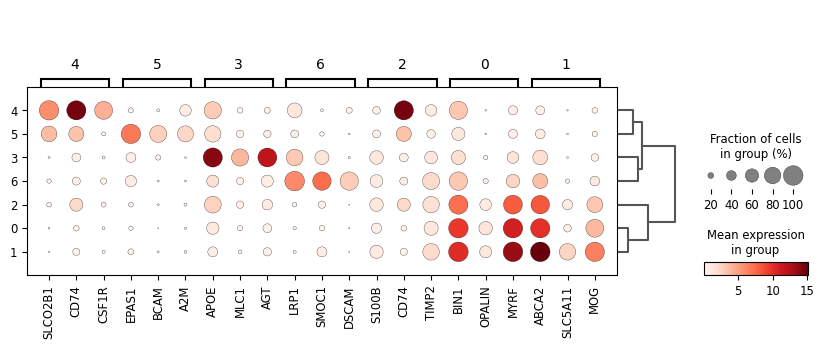

In [27]:
# redefine overlaps_cell in transcripts, for nuclei
if "nuclei" in metadata["segmentation_method"][0]:
    transcripts = sdata["transcripts"].compute()
    transcripts["overlaps_cell"] = transcripts["overlaps_nucleus"].astype(bool)
    sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)
    print("Redefined overlaps_cell in transcripts using nuclei segmentation.")

    # 1) Clustering
clustering_pipeline(sdata)

    # 2) Segmentation-free SAiNSC
troutpy.pp.segmentation_free_sainsc(
        sdata,
        celltype_key="leiden")

In [ ]:
# 4) Define extracellular
troutpy.pp.define_extracellular(sdata, layer="transcripts", method="sainsc", copy=False)

Cosine similarity threshold for extracellular definition: 0.6096240282058716


In [32]:
import dask.dataframe as dd
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.stats as stats
import spatialdata
import spatialdata as sd
import squidpy as sq
from scipy.spatial import cKDTree
from scipy.spatial.distance import euclidean
from scipy.stats import poisson, spearmanr
from spatialdata import SpatialData
from troutpy.pp.aggregate import aggregate_extracellular_transcripts


def create_xrna_metadata(sdata: SpatialData, layer: str = "transcripts", gene_key: str = "gene", copy: bool = False) -> SpatialData | None:
    """
    Creates a new table within the SpatialData object that contains a 'gene' column with the unique gene names extracted from the specified points layer.

    Parameters
    ----------
    sdata: spatialdata.SpatialData
        The SpatialData object to modify.
    layer: str
        The name of the layer in `sdata.points` from which to extract gene names. Default is 'transcripts'.
    gene_key: str
        The key in the `layer` dataframe that contains the gene names.Default is 'feature_name'.
    copy: bool
        If `True`, returns a copy of the `SpatialData` object with the new table added.

    Returns
    -------
    spatialdata.SpatialData
        If `copy` is `True`, returns a copy of the modified `SpatialData` object. Otherwise, returns `None`.
    """
    # Check if the specified points layer exists
    if layer not in sdata.points:
        raise ValueError(f"Points layer '{layer}' not found in sdata.points.")

    # Extract unique gene names from the specified points layer
    points_data = sdata.points[layer]
    if gene_key not in points_data.columns:
        raise ValueError(f"The specified points layer '{layer}' does not contain a '{gene_key}' column.")

    unique_genes = points_data[gene_key].compute().unique().astype(str)

    # Create a DataFrame for unique genes
    gene_metadata = pd.DataFrame(index=unique_genes)

    # Convert to AnnData and then to SpatialData table model
    exrna_adata = sc.AnnData(var=gene_metadata)
    metadata_table = sd.models.TableModel.parse(exrna_adata)

    # Add the new table to the SpatialData object
    sdata.tables["xrna_metadata"] = metadata_table

    print(f"Added 'xrna_metadata' table with {len(unique_genes)} unique genes to the SpatialData object.")

    # Return copy or modify in place
    return sdata if copy else None

No control probe could be found. Automatic noise probe calculation will be performed instead
8.0


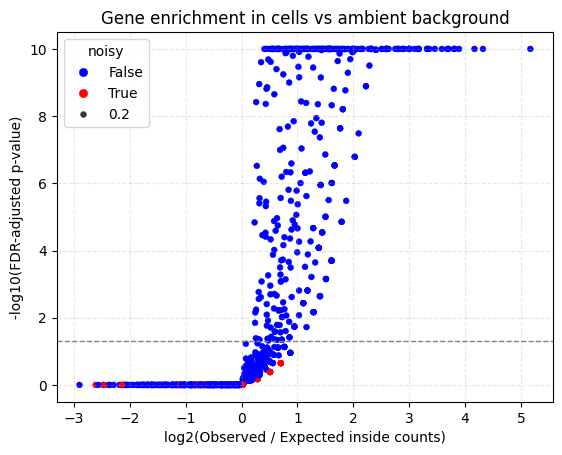

In [44]:
quantify_overexpression(sdata)
troutpy.tl.extracellular_enrichment(sdata, gene_key="gene")

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import poisson
from statsmodels.stats.multitest import multipletests
import seaborn as sns
import matplotlib.pyplot as plt


def quantify_overexpression(
    sdata: SpatialData,
    codeword_key: str = "control_probe",
    control_codewords: list = None,
    gene_key: str = "gene",
    layer: str = "transcripts",
    percentile_threshold: float = 100,
    copy=False, noise_gene_calculation=False
) -> SpatialData:
    """Compare extracellular transcript counts per gene to those of control codewords(e.g., negative probes or known noisy features) to estimate overexpression.

    Parameters:
    ----------
    sdata : spatialdata.SpatialData
        The input SpatialData object with a 'points' layer (typically 'transcripts').
    codeword_key : str
        Column name to identify control features in the points table.
    control_codewords : list
        List of values in `codeword_key` to treat as control probes. If None, 
        assumes `True`-labeled control probes.
    gene_key : str
        Column name indicating the gene identifier.
    layer : str
        Layer within `sdata.points` containing transcript data.
    percentile_threshold : float
        Percentile of control probe counts to use as noise threshold (e.g., 95).
    copy : bool
        If True, return a modified copy of the SpatialData. If False, modify in-place.
    noise_gene_calculation : bool
        If True or if no control probes found, automatically infer noisy genes using `identify_noisy_genes`.

    Returns:
    -------
    SpatialData
        Returns the modified SpatialData if `copy=True`, otherwise None.
    """
    # Compute the data
    data = sdata.points[layer][np.unique(["extracellular", codeword_key, gene_key]).tolist()].compute()

    data = data[data["extracellular"]]
    if control_codewords is None:
        control_codewords = [True]

    # Ensure control_codewords is a list
    if isinstance(control_codewords, str):
        control_codewords = [control_codewords]

    # Get counts per control feature
    is_control = list(data[codeword_key].isin(control_codewords))
    control_data = data[data[codeword_key].isin(control_codewords)]
    if np.sum(is_control)==0 or noise_gene_calculation==True:
        print('No control probe could be found. Automatic noise probe calculation will be performed instead')
        noisy_genes, results_df=identify_noisy_genes(sdata, plot=True, fdr_threshold=0.05)
        control_data = data[data[gene_key].isin(noisy_genes)]
    
    # gene_data = data[~data[codeword_key].isin(control_codewords)]

    control_counts = control_data[gene_key].value_counts()
    gene_counts = data[gene_key].value_counts()  # we include all because we will test for all
    n2c = dict(zip(data[gene_key], is_control, strict=False))
    bool_control = []
    for g in gene_counts.keys():
        bool_control.append(n2c.get(g, True))

    # Compute percentile-based threshold
    threshold = np.percentile(control_counts.values, percentile_threshold)

    # Calculate log fold ratio
    scores_per_gene = pd.DataFrame({"count": gene_counts, "logfoldratio_over_noise": np.log(gene_counts / threshold), "control_probe": bool_control})

    # Perform Poisson test
    p_values = {}
    control_mean = np.mean(control_counts.values)  # Expected background noise
    for gene in gene_counts.index:
        observed_count = gene_counts[gene]
        p_value = 1 - poisson.cdf(observed_count - 1, control_mean)  # One-tailed test
        p_values[gene] = p_value

    scores_per_gene["p_value_Poisson"] = scores_per_gene.index.map(p_values)

    # Store results in xrna_metadata
    try:
        sdata["xrna_metadata"]
    except KeyError:
        create_xrna_metadata(sdata, layer=layer, gene_key=gene_key)

    # select columns that will be overwritten
    existing_cols = sdata["xrna_metadata"].var.columns
    for col in scores_per_gene.columns:
        if col in existing_cols:
            sdata["xrna_metadata"].var.drop(columns=[col], inplace=True)

    sdata["xrna_metadata"].var = sdata["xrna_metadata"].var.join(scores_per_gene)

    return sdata if copy else None


def identify_noisy_genes(sdata, plot=True, fdr_threshold=0.05):
    """Identify noisy genes based on statistical enrichment of inside-cell counts compared to expected background levels estimated from outside-cell counts.

    Parameters:
    ----------
    sdata : spatialdata.SpatialData
        A SpatialData object with at least a 'transcripts' layer and a boolean 'overlaps_cell' column indicating intracellular transcripts.
    plot : bool
        Whether to generate a volcano plot of log-fold change vs adjusted p-value.
    fdr_threshold : float
        Adjusted p-value cutoff (FDR) for defining significant enrichment.

    Returns:
    -------
    noisy_genes : list
        List of gene names identified as likely noise.
    results_df : pandas.DataFrame
        DataFrame with observed, expected counts, p-values, log fold changes,and 'noisy' flags per gene.
    """
    # Extract transcript data
    df = sdata["transcripts"][["overlaps_cell", "gene"]].compute()
    inside = df[df["overlaps_cell"] == True]
    outside = df[df["overlaps_cell"] == False]

    # Count total transcripts
    total_inside = len(inside)
    total_outside = len(outside)

    # Compute background rate from outside (ambient)
    outside_counts = outside["gene"].value_counts()
    background_rate = outside_counts / total_outside

    # Observed inside-cell counts
    inside_counts = inside["gene"].value_counts()
    min_inside_count = np.percentile(inside_counts, 10) # take the percentile 10 of genes less expressed
    print(str(min_inside_count))
    # Union of genes
    all_genes = set(background_rate.index).union(set(inside_counts.index))

    # Compute expected counts and p-values
    expected = {g: background_rate.get(g, 0) * total_inside for g in all_genes}
    observed = {g: inside_counts.get(g, 0) for g in all_genes}
    pvals = {g: poisson.sf(observed[g] - 1, expected[g]) for g in all_genes}

    # Multiple testing correction
    genes = list(pvals.keys())
    raw_pvals = list(pvals.values())
    _, adj_pvals, _, _ = multipletests(raw_pvals, method="fdr_bh")

    # Build results table
    results_df = pd.DataFrame({
        "gene": genes,
        "observed_inside": [observed[g] for g in genes],
        "expected_inside": [expected[g] for g in genes],
        "raw_pval": raw_pvals,
        "adj_pval": adj_pvals,
    }).set_index("gene")

    # Compute log fold change
    results_df["log2_fc"] = np.log2((results_df["observed_inside"] + 1) / (results_df["expected_inside"] + 1))

    # Identify noisy genes: not significantly enriched AND low inside count
    results_df["noisy"] = (results_df["adj_pval"] > fdr_threshold) & \
                          (results_df["observed_inside"] < min_inside_count)

    noisy_genes = results_df[results_df["noisy"]].index.tolist()

    # Optional plot
    if plot:
        sns.scatterplot(
            data=results_df,
            x="log2_fc",
            y=-np.log10(results_df["adj_pval"] + 1e-10),
            hue="noisy", size=0.2,
            palette={True: "red", False: "blue"},
            edgecolor=None
        )
        plt.axhline(-np.log10(fdr_threshold), color="gray", linestyle="--", linewidth=1)
        plt.xlabel("log2(Observed / Expected inside counts)")
        plt.ylabel("-log10(FDR-adjusted p-value)")
        plt.title("Gene enrichment in cells vs ambient background")
        plt.yscale("linear")
        plt.grid(True, linestyle="--", alpha=0.3)
        plt.show()

    return noisy_genes, results_df


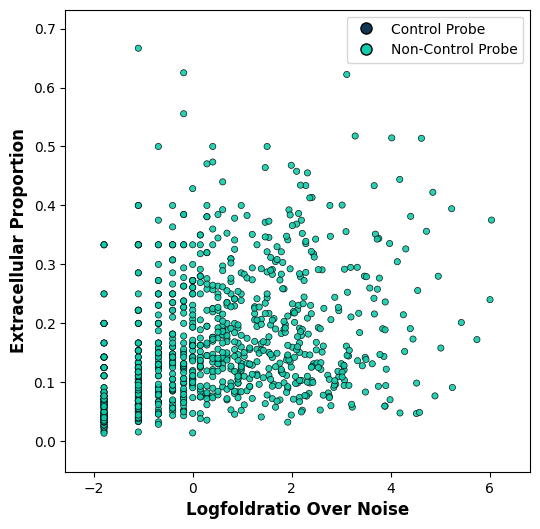

In [45]:
troutpy.pl.metric_scatter(
            sdata,
            x='logfoldratio_over_noise',
            y='extracellular_proportion',size=20
        )

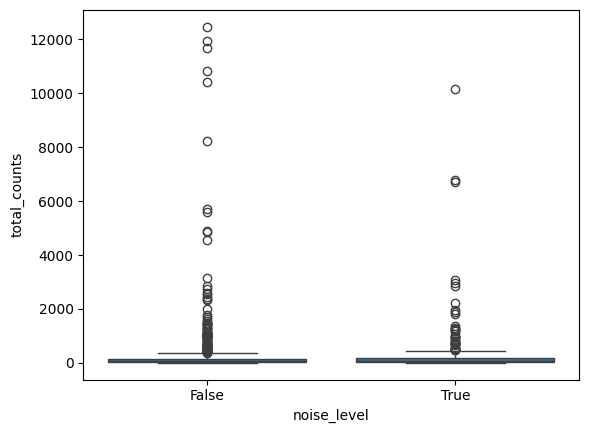

In [131]:
from shapely.geometry import shape
from shapely.geometry import box

# Assuming sdata['shapes'] contains a list of geometries (polygons)
areas = []
for polygon in sdata["shapes"].index:
    # Create a Shapely geometry object
    geom = sdata["shapes"].loc[polygon, "geometry"]

    # Calculate the area of the polygon
    areas.append(geom.area)
# Add the areas to the sdata object as a new field

cell_area = np.sum(areas)

# Define a bounding box around your region of interest
minx, miny, maxx, maxy = sdata["shapes"]["geometry"].total_bounds
bounding_box = box(minx, miny, maxx, maxy)

all_area = bounding_box.area
out_area = all_area - cell_area
cell2out_ratio = cell_area / out_area

allgene = sdata["transcripts"][["overlaps_cell", "gene"]].compute()

import pandas as pd

transcript_x_cell = pd.crosstab(allgene["gene"], allgene["overlaps_cell"])

transcript_x_cell["total_counts"] = transcript_x_cell.sum(axis=1)
transcript_x_cell["noise_level"] = transcript_x_cell[True] * cell2out_ratio < transcript_x_cell[False]
noise_genes = transcript_x_cell[transcript_x_cell["noise_level"]]
import seaborn as sns

sns.boxplot(data=transcript_x_cell, x="noise_level", y="total_counts")
transcript_x_cell["above_noise"] = transcript_x_cell["total_counts"] > np.median(noise_genes["total_counts"])
noise_threshold = np.median(noise_genes["total_counts"])
noisy_genes = transcript_x_cell.loc[transcript_x_cell["total_counts"] < noise_threshold, :].index

In [112]:
import numpy as np
from shapely.ops import unary_union
from shapely.geometry import box

# --- 1. compute cell vs. background area ---
cells = sdata["shapes"].geometry

# pick buffer‑width r (in same units as your geometry)
# e.g. half the median cell radius:
median_radius = np.median([np.sqrt(poly.area / np.pi) for poly in cells])
r = median_radius * 0.5

# build per‑cell rings and union them
rings = [poly.buffer(r).difference(poly) for poly in cells]
ring_union = unary_union(rings)

A_bg = ring_union.area
A_cell = sum(poly.area for poly in cells)

# --- 2. count transcripts in/out as before ---
allgene = sdata["transcripts"][["overlaps_cell", "gene"]].compute()
transcript_x_cell = pd.crosstab(allgene["gene"], allgene["overlaps_cell"]).rename(columns={False: "out", True: "in"})

# --- 3. per‑gene background density ---
transcript_x_cell["lambda_bg"] = transcript_x_cell["out"] / A_bg

# --- 4. per‑gene Poisson threshold & p‑value ---
from scipy.stats import poisson

transcript_x_cell["T95"] = poisson.ppf(0.95, transcript_x_cell["lambda_bg"] * A_cell)
transcript_x_cell["p_value"] = 1 - poisson.cdf(transcript_x_cell["in"] - 1, transcript_x_cell["lambda_bg"] * A_cell)

# now you have per‑gene thresholds and p‑values

<Axes: xlabel='total_counts', ylabel='Count'>

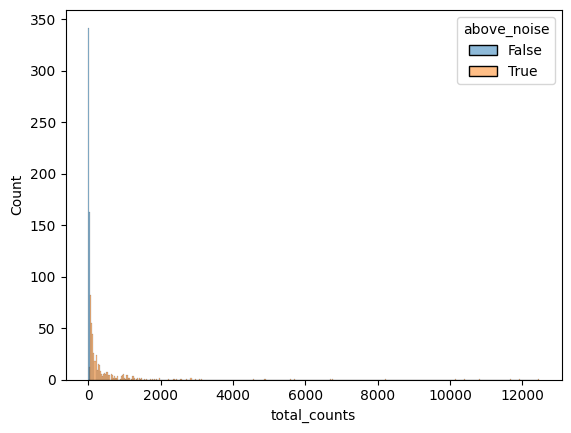

In [106]:
sns.histplot(data=transcript_x_cell, x="total_counts", hue="above_noise")

In [ ]:
import numpy as np

# Original data (up to the mean)
lower_half = np.array([3, 4, 5, 6])  # example values
mu = 6  # known mean

# Mirror around the mean
upper_half = 2 * mu - lower_half

# Combine both halves
full_data = np.concatenate([lower_half, upper_half])

# Compute standard deviation
std_dev = np.std(full_data)
print("Estimated standard deviation:", std_dev)

In [33]:
cell_area

259416.82064801542

In [32]:
out_area

719092.9399738894

In [ ]:
# Union of all polygon geometries
# combined = unary_union(sdata['shapes']['geometry'].values)

# Compute area outside the polygons but inside the bounding box
# outside_area = bounding_box.area - combined.area


In [23]:
sdata["shapes"]["geometry"]

EntityID
2451067200000100001    POLYGON ((360.206 -30.57, 361.288 -29.166, 364...
2451067200000100002    POLYGON ((380.693 -24.504, 380.446 -23.47, 380...
2451067200000100003    POLYGON ((486.417 -29.71, 486.83 -28.326, 488....
2451067200000100004    POLYGON ((427.014 -30.069, 429.511 -27.65, 432...
2451067200000100006    POLYGON ((195.151 -29.449, 195.516 -28.611, 20...
                                             ...                        
2451067200051100064    POLYGON ((915.399 1034.236, 915.821 1037.855, ...
2451067200052100057    POLYGON ((1026.995 1014.86, 1030.088 1017.872,...
2451067200052100077    POLYGON ((1031.171 1024.749, 1032.215 1025.734...
2451067200052100080    POLYGON ((1015.649 1027.27, 1016.461 1028.786,...
2451067200052100089    POLYGON ((1031.8 1040.334, 1034.067 1040.966, ...
Name: geometry, Length: 1707, dtype: geometry

Proportion of cells retained after filtering: 86.07%
Final adata shape: (1427, 979)


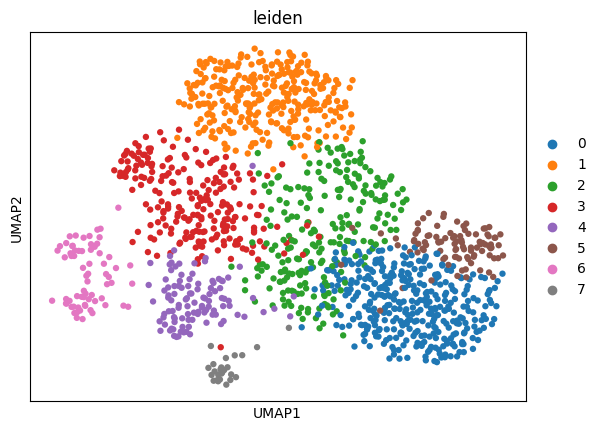

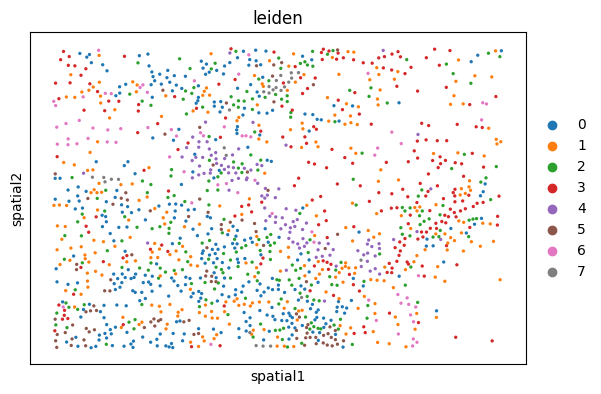

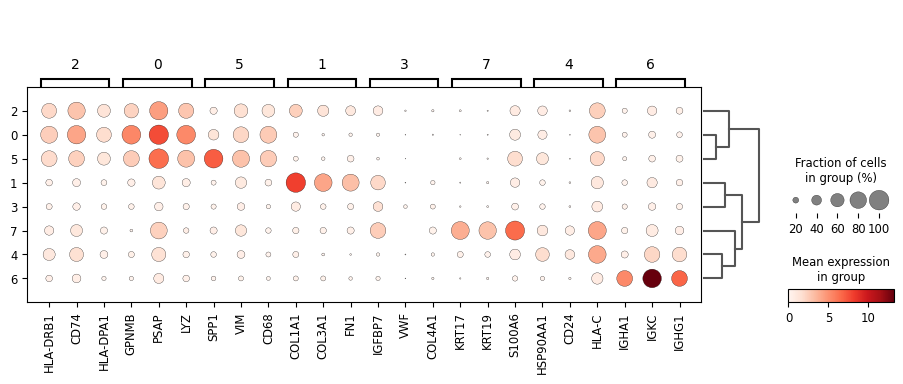

AnnData object with n_obs × n_vars = 1427 × 979
    obs: 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'fov_labels', 'cell_ID', 'region', 'x', 'y', 'n_genes', 'n_counts', 'leiden'
    var: 'n_cells'
    uns: 'spatialdata_attrs', 'log1p', 'pca', 'neighbors', 'umap', 'leiden', 'dendrogram_leiden', 'rank_genes_groups', 'leiden_colors'
    obsm: 'global', 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'distances', 'connectivities'

In [142]:
inpath = "/media/sergio/Meninges/troutpy/rois/cosmx_hgsoc"

saving_path = os.path.join(inpath, "figures")
if not os.path.exists(saving_path):
    os.makedirs(saving_path)
sdata = sd.read_zarr(os.path.join(inpath, "data.zarr"))

# clustering cells
clustering_pipeline(sdata)

In [53]:
from functools import partial
from multiprocessing import Pool

import numpy as np
import pandas as pd
import polars as pl
import spatialdata as sd
from sainsc import LazyKDE  # assuming LazyKDE is available
from scipy.sparse import coo_matrix
from sklearn.neighbors import KDTree
from spatialdata import SpatialData


def compute_extracellular_counts(data_extracell):  # would be good to change the name of this function
    """
    Compute observed, expected, and fold ratio for extracellular transcript counts.

    Parameters
    ----------
    data_extracell (pd.DataFrame)
        Data with extracellular transcripts.

    Returns
    -------
    pd.DataFrame
        Dataframe with observed, expected counts, fold ratios, and gene categories.
    """
    extracellular_counts = data_extracell.groupby("feature_name").count()
    extracellular_counts = pd.DataFrame({"observed": extracellular_counts.iloc[:, 0]})
    extracellular_counts["expected"] = int(extracellular_counts["observed"].sum() / extracellular_counts.shape[0])

    # Calculate fold ratios
    extracellular_counts["fold_ratio"] = np.log(extracellular_counts["observed"] / extracellular_counts["expected"])

    # Map gene categories
    gene2cat = dict(zip(data_extracell["feature_name"], data_extracell["codeword_category"], strict=False))
    extracellular_counts["codeword_category"] = extracellular_counts.index.map(gene2cat)

    return extracellular_counts


def define_extracellular(
    sdata: SpatialData,
    layer: str = "transcripts",
    method: str = "segmentation_free",
    min_prop_of_extracellular: float = 0.8,
    unassigned_tag: str = "UNASSIGNED",
    copy: bool = False,
    percentile_threshold: float = 10,
):
    """
    Identifies extracellular transcripts based on the specified method and updates the spatial data object accordingly.

    Parameters
    ----------
    sdata : SpatialData
        A spatial data object containing transcriptomic information.
    layer : str
        The layer in `sdata.points` containing the transcript data to process.
    method : str
        The method to define extracellular transcripts. Options:
            - 'spots2regions': Uses segmentation-free clustering results.
            - 'sainsc': Uses sainsc-derived signature matching.
            - 'nuclei': Uses overlap with nuclear annotations to classify extracellular transcripts.
            - 'cells': Classifies transcripts not assigned to a cell as extracellular.
    min_prop_of_extracellular : float, optional
        Minimum proportion of transcripts in a cluster required to be extracellular for it to be classified as such
        (used only with the 'spots2regions' method).
    unassigned_tag : str, optional
        Tag indicating transcripts not assigned to any cell.
    copy : bool
        If True, returns a copy of the updated spatial data. If False, updates the `sdata` object in-place.

    Returns
    -------
    Optional[SpatialData]
        If `copy` is True, returns a copy of the updated `sdata` object.
        Otherwise, updates the `sdata` object in-place and returns None.

    Notes
    -----
    - For the 'spots2regions' method, clustering results are used to determine extracellular transcripts.
    - The 'sainsc' method defines extracellular transcripts as those that are not assigned to any cell
      and whose local signature (match_cell_signature) is not False.
    - The 'nuclei' method classifies transcripts outside nuclei as extracellular.
    - The 'cells' method classifies transcripts unassigned to cells as extracellular.
    """
    import pandas as pd  # Ensure pandas is imported, if not already available in sdata environment

    # Compute the data layer from the spatial data object
    data = sdata.points[layer].compute()

    # Method: Segmentation-free clustering (spots2regions)
    if method == "spots2regions":
        data["overlaps_cell"] = (data["cell_id"] != unassigned_tag).astype(int)
        overlapping_cell = pd.crosstab(data["segmentation_free_clusters"], data["overlaps_cell"])
        # Compute proportions and define extracellular clusters
        cluster_totals = overlapping_cell.sum(axis=1)
        cluster_proportions = overlapping_cell.div(cluster_totals, axis=0)
        extracellular_clusters = cluster_proportions[cluster_proportions.loc[:, 0] >= min_prop_of_extracellular].index
        data["extracellular"] = ~data["segmentation_free_clusters"].isin(extracellular_clusters)

    # Method: Using sainsc analysis results
    elif method == "sainsc":
        # Here we define extracellular transcripts as those that:
        # 1. Are not assigned to any cell (cell_id equals unassigned_tag), and
        # 2. Have a match_cell_signature that is not False (i.e. have a cell-like signature locally).
        cosine_sim_threshold = np.nanpercentile(
            data.loc[data["overlaps_cell"] == True, "cosine_similarity"], percentile_threshold
        )
        data["match_cell_signature"] = data["cosine_similarity"] > cosine_sim_threshold
        data["extracellular"] = (data["overlaps_cell"] == False) & (data["match_cell_signature"] == False)
        print(f"Cosine similarity threshold for extracellular definition: {cosine_sim_threshold}")
    # Method: Based on nuclei overlap
    elif method == "nuclei":
        data["extracellular"] = data["overlaps_nucleus"] != 1

    # Method: Based on cell assignment
    elif method == "cells":
        data["extracellular"] = data["cell_id"] == unassigned_tag

    # Unsupported method
    else:
        raise ValueError(
            f"Unknown method: {method}. Supported methods are 'spots2regions', 'sainsc', 'nuclei', and 'cells'."
        )

    # Update the spatial data object with the new extracellular column
    sdata.points[layer] = sd.models.PointsModel.parse(data)

    return sdata if copy else None


def filter_xrna(
    sdata,
    min_counts=None,
    min_extracellular_proportion=None,
    control_probe=None,
    min_logfoldratio_over_noise=1,
    min_morani=None,
    gene_key="feature_name",
    filter_cellular=False,
    copy=False,
):
    """
    Filters xRNA based on specified criteria and updates the sdata object.

    Parameters
    ----------
        sdata: dict-like
            Spatial data object containing xRNA metadata and transcript information.
        min_counts: int, optional
            Minimum count threshold for xRNA selection.
        min_extracellular_proportion: float, optional
            Minimum extracellular proportion threshold for xRNA selection.
        control_probe: bool, optional
            If False, filters out control probes.
        min_logfoldratio_over_noise: float, default=1
            Minimum log fold-change over noise threshold for xRNA selection.
        min_morani: float, optional
            Minimum Moran's I threshold for spatial autocorrelation.
        gene_key: str, default='feature_name'
            Key for accessing gene names in transcript tables.
        filter_cellular: bool, default=False
            If True, also filters the cellular table.
        copy: bool, default=False
            If True, returns a filtered copy of sdata; otherwise, modifies in place.

    Returns
    -------
        dict-like or None
            Filtered sdata if copy=True, else modifies sdata in place and returns None.
    """
    if copy:
        sdata = sdata.copy()

    # Select genes based on the first provided criterion
    if min_counts is not None:
        selected_genes = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var["count"] > min_counts].index
    elif min_extracellular_proportion is not None:
        selected_genes = (
            sdata["xrna_metadata"]
            .var[sdata["xrna_metadata"].var["extracellular_proportion"] > min_extracellular_proportion]
            .index
        )
    elif control_probe is False:
        selected_genes = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var["control_probe"] == False].index
    elif min_logfoldratio_over_noise is not None:
        selected_genes = (
            sdata["xrna_metadata"]
            .var[sdata["xrna_metadata"].var["logfoldratio_over_noise"] > min_logfoldratio_over_noise]
            .index
        )
    elif min_morani is not None:
        selected_genes = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var["moran_I"] > min_morani].index
    else:
        return sdata if copy else None

    # Filter transcripts
    sdata["transcripts"] = sdata["transcripts"][sdata["transcripts"][gene_key].compute().isin(selected_genes)]

    # Filter other related tables safely
    for key in ["segmentation_free_table", "xrna_metadata"]:
        if key in sdata:
            try:
                sdata[key] = sdata[key][:, sdata[key].var.index.isin(selected_genes)]
            except Exception:
                pass

    # Filter source_score and target_score by obs
    for key in ["source_score", "target_score"]:
        if key in sdata:
            try:
                sdata[key] = sdata[key][sdata[key].obs[gene_key].isin(selected_genes), :]
            except Exception:
                pass

    # Filter cellular table if requested
    if filter_cellular and "table" in sdata:
        try:
            sdata["table"] = sdata["table"][:, sdata["table"].var.index.isin(selected_genes)]
        except Exception:
            pass

    return sdata if copy else None


def process_dataframe(df: pl.DataFrame, binsize: float, n_threads: int = 4):
    """
    Process a Polars DataFrame by binning spatial coordinates,
    converting the gene column to categorical, and constructing sparse matrices for each gene.
    """
    # Compute bin coordinates.
    df = df.with_columns((df["x"] / binsize).floor().alias("bin_x"), (df["y"] / binsize).floor().alias("bin_y"))
    # Shift coordinates so that bins start at zero.
    df = df.with_columns(
        (df["bin_x"] - df["bin_x"].min()).cast(pl.Int32).alias("bin_x"),
        (df["bin_y"] - df["bin_y"].min()).cast(pl.Int32).alias("bin_y"),
    )
    # Ensure count column exists; if not, add one.
    if "count" not in df.columns:
        df = df.with_columns(pl.lit(1, dtype=pl.UInt32).alias("count"))
    else:
        df = df.with_columns(df["count"].cast(pl.UInt32))
    # Make gene column categorical.
    df = df.with_columns(df["gene"].cast(pl.Categorical))

    # Determine grid shape from binned coordinates.
    shape = (df["bin_x"].max() + 1, df["bin_y"].max() + 1)

    # Partition by gene for parallel processing.
    gene_groups = df.partition_by("gene", maintain_order=False)
    process_gene_partial = partial(process_gene, shape=shape)

    with Pool(n_threads) as pool:
        gene_results = pool.map(process_gene_partial, gene_groups)

    results = {gene: matrix for gene, matrix in gene_results}
    return results, shape, df


def process_gene(group, shape):
    """
    Process a group corresponding to one gene to build a sparse matrix.
    """
    gene_name = group["gene"][0]
    x = group["bin_x"].to_numpy()
    y = group["bin_y"].to_numpy()
    counts = group["count"].to_numpy()
    sparse_matrix = coo_matrix((counts, (x, y)), shape=shape).tocsr()
    return gene_name, sparse_matrix


def segmentation_free_sainsc(
    sdata,
    binsize=3,
    celltype_key="leiden",
    background_filter=0.4,
    gaussian_kernel_key=2.5,
    n_threads=16,
    resolution=1000,
    codeword_category="predesigned_gene",
    return_sainsc=False,
    copy=False,
    # Defaults for missing bin info
    default_cell_type="unknown",
    default_numeric=np.nan,
):
    """
    Process an sdata object by running an integrated sainsc analysis pipeline with configurable parameters.

    Steps:
      1. Extract and filter transcript data.
      2. Compute cell type signatures.
      3. For KDE/cell type assignment, use only transcripts with overlapping genes.
      4. Bin all transcripts.
      5. Merge the bin-level metadata (computed from successful bins) back to the full transcript set.
      6. For transcripts that do NOT obtain metadata via the merge, assign them the data
         from their spatially closest neighbor (based on "x", "y").
    """
    # --- 1. Prepare Transcript Data ---
    transcripts_all = sdata.points["transcripts"][["gene", "x", "y", "transcript_id"]].compute().reset_index(drop=True)
    # transcripts_all = transcripts_all[transcripts_all["codeword_category"] == codeword_category]
    transcripts_all = transcripts_all[transcripts_all["gene"].astype(str) != "nan"]

    # Create a full DataFrame for binning (all transcripts are retained)
    transcripts_full = pl.from_pandas(
        transcripts_all[["gene", "x", "y"]].copy(), schema_overrides={"gene": pl.Categorical}
    )

    # --- 2. Retrieve Cell Expression Data & Compute Signatures ---
    adata = sdata["table"]
    expr = adata.to_df()
    expr["cell type"] = adata.obs[celltype_key]
    signatures = expr.groupby("cell type").mean().transpose()

    # --- 3. Determine Overlapping Genes for Analysis ---
    common_genes = set(transcripts_all["gene"].unique()).intersection(set(signatures.index))
    transcripts_analysis = transcripts_full.filter(pl.col("gene").is_in(list(common_genes)))

    # --- 4. Create Brain Object Using LazyKDE (Analysis on overlapping genes) ---
    brain = LazyKDE.from_dataframe(transcripts_analysis, resolution=resolution, binsize=binsize, n_threads=n_threads)

    # --- 5. Process All Transcripts into Binned Data ---
    _, shape, transcript2bin_info = process_dataframe(transcripts_full, binsize=binsize, n_threads=n_threads)
    transcript2bin_info = transcript2bin_info.to_pandas()
    transcript2bin_info["bin_x_y_id"] = (
        transcript2bin_info["bin_x"].astype(str) + "_" + transcript2bin_info["bin_y"].astype(str)
    )

    # --- 6. Prepare Unique Identifiers for Merging ---
    # Round coordinates to create matching keys.
    transcripts_all["x"] = transcripts_all["x"].round(4)
    transcripts_all["y"] = transcripts_all["y"].round(4)
    transcript2bin_info["x"] = transcript2bin_info["x"].round(4)
    transcript2bin_info["y"] = transcript2bin_info["y"].round(4)
    transcripts_all["xy"] = transcripts_all["x"].astype(str) + "_" + transcripts_all["y"].astype(str)
    transcript2bin_info["xy"] = transcript2bin_info["x"].astype(str) + "_" + transcript2bin_info["y"].astype(str)

    # --- 7. Run KDE, Background Filtering and Cell Type Assignment ---
    brain.calculate_total_mRNA()
    brain.gaussian_kernel(gaussian_kernel_key, unit="um")
    brain.calculate_total_mRNA_KDE()
    brain.filter_background(background_filter)
    brain.assign_celltype(signatures, log=True)

    # --- 8. Compute Bin-level Features from Brain ---
    celltype_flat = brain.celltype_map.flatten()
    assignment_score_flat = brain.assignment_score.flatten()
    cosine_similarity_flat = brain.cosine_similarity.flatten()

    n_rows, n_cols = brain.celltype_map.shape
    x_coords, y_coords = np.meshgrid(np.arange(n_cols), np.arange(n_rows))
    x_coords = x_coords.flatten()
    y_coords = y_coords.flatten()

    output_df = pd.DataFrame(
        {
            "bin_x": x_coords,
            "bin_y": y_coords,
            "cell type": celltype_flat,
            "assignment_score": assignment_score_flat,
            "cosine_similarity": cosine_similarity_flat,
        }
    )
    num2ct = dict(zip(range(len(brain.celltypes)), brain.celltypes, strict=False))
    output_df["cell type"] = output_df["cell type"].map(num2ct)
    output_df["bin_x_y_id"] = output_df["bin_y"].astype(str) + "_" + output_df["bin_x"].astype(str)

    # Build mapping dictionaries.
    bin2celltype = dict(zip(output_df["bin_x_y_id"], output_df["cell type"], strict=False))
    bin2cosine = dict(zip(output_df["bin_x_y_id"], output_df["cosine_similarity"], strict=False))
    bin2assign = dict(zip(output_df["bin_x_y_id"], output_df["assignment_score"], strict=False))

    # --- 9. Merge Bin-level Features for Transcripts That Were Successfully Binned ---
    # Merge on the unique "xy" identifier.
    bin_features = transcript2bin_info[["xy", "bin_x_y_id"]].drop_duplicates()
    bin_features["closest_cell_type"] = bin_features["bin_x_y_id"].map(bin2celltype)
    bin_features["cosine_similarity"] = bin_features["bin_x_y_id"].map(bin2cosine)
    bin_features["assignment_score"] = bin_features["bin_x_y_id"].map(bin2assign)

    # Perform a left merge so all transcripts are retained.
    merged = pd.merge(transcripts_all, bin_features, on="xy", how="left")

    # --- 10. Apply Nearest-Neighbor Assignment Only When Merge Failed ---
    missing_mask = merged["closest_cell_type"].isna()
    if missing_mask.sum() > 0:
        # Use only transcripts that have valid bin metadata.
        valid = merged[~missing_mask]
        missing = merged[missing_mask]
        if not valid.empty:
            # Build KDTree using the positions (x,y) of valid transcripts.
            tree = KDTree(valid[["x", "y"]].values)
            distances, indices = tree.query(missing[["x", "y"]].values, k=1)
            nn_metadata = valid.iloc[indices.flatten()].reset_index(drop=True)
            for col in ["closest_cell_type", "cosine_similarity", "assignment_score"]:
                missing[col] = nn_metadata[col].values
            merged.loc[
                missing_mask, ["closest_cell_type", "cosine_similarity", "assignment_score", "match_cell_signature"]
            ] = missing[["closest_cell_type", "cosine_similarity", "assignment_score"]]

    # --- 11. Fill Any Remaining Missing Values with Defaults ---
    merged["closest_cell_type"] = merged["closest_cell_type"].fillna(default_cell_type)
    merged["cosine_similarity"] = merged["cosine_similarity"].fillna(default_numeric)
    merged["assignment_score"] = merged["assignment_score"].fillna(default_numeric)

    # Optionlly, force the correct data types
    merged["closest_cell_type"] = merged["closest_cell_type"].astype(str)
    merged["cosine_similarity"] = merged["cosine_similarity"].astype(float)
    merged["assignment_score"] = merged["assignment_score"].astype(float)

    # --- 12. Update the sdata Object ---
    transi = sdata.points["transcripts"].compute().copy()
    transi["xy"] = transi["x"].round(4).astype(str) + "_" + transi["y"].round(4).astype(str)
    # Drop duplicated columns if needed
    columns_to_remove = ["closest_cell_type", "cosine_similarity", "assignment_score"]
    try:
        transi = transi.drop(columns=[col for col in columns_to_remove if col in transi.columns])
    except Exception:
        pass
    # Then merge safely
    transi = pd.merge(
        transi,
        merged[["xy", "closest_cell_type", "cosine_similarity", "assignment_score"]],
        on="xy",
        how="left",
    )
    # Fill any remaining missing entries as a safeguard (should be none now)
    transi["closest_cell_type"] = transi["closest_cell_type"].fillna(default_cell_type).astype(str)
    transi["cosine_similarity"] = transi["cosine_similarity"].fillna(default_numeric).astype(float)
    transi["assignment_score"] = transi["assignment_score"].fillna(default_numeric).astype(float)
    # Update the transcripts layer
    sdata.points["transcripts"] = sd.models.PointsModel.parse(transi)

    # --- 13. Return Results ---
    sainsc_output = {"brain": brain, "transcript2bin_info": transcript2bin_info, "output_df": output_df}
    if return_sainsc:
        return sdata, sainsc_output
    else:
        return sdata if copy else None

In [54]:
sdata = sd.read_zarr(os.path.join(inpath, "data_processed.zarr"))

In [56]:
segmentation_free_sainsc(
    sdata, binsize=40, celltype_key="leiden", background_filter=0.4, gaussian_kernel_key=30.0, n_threads=16
)

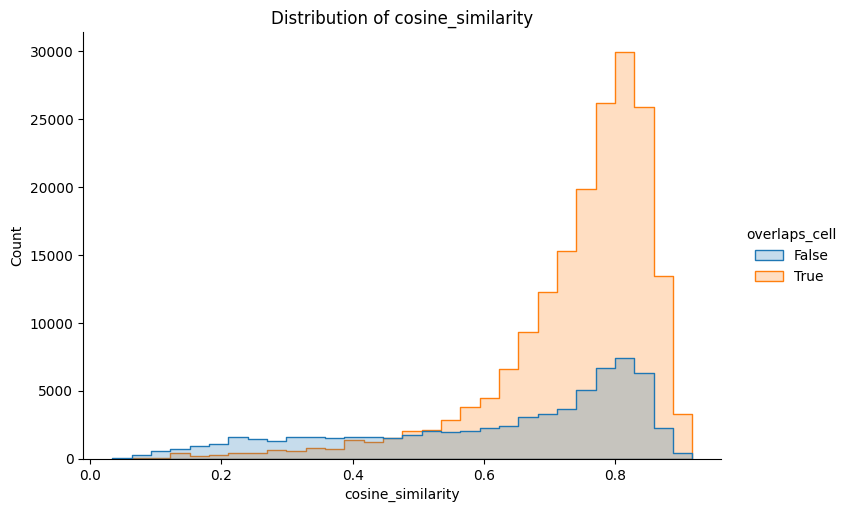

In [57]:
troutpy.pl.histogram(sdata, x="cosine_similarity", hue="overlaps_cell", save=True, figures_path=saving_path)

In [58]:
sdata

SpatialData object, with associated Zarr store: /media/sergio/Meninges/troutpy/rois/cosmx_hgsoc/data_processed.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (3, 4200, 5600), (3, 2100, 2800), (3, 1050, 1400)
├── Labels
│     └── 'labels': DataTree[yx] (4200, 5600), (2100, 2800), (1050, 1400)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 19) (2D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 19) (2D points)
├── Shapes
│     ├── 'grid_squares': GeoDataFrame shape: (197835, 1) (2D shapes)
│     └── 'shapes': GeoDataFrame shape: (1658, 2) (2D shapes)
└── Tables
      ├── 'segmentation_free_table': AnnData (197835, 979)
      ├── 'table': AnnData (1427, 979)
      └── 'xrna_metadata': AnnData (0, 979)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), labels (Labels), extracellular_transcripts (Points), transcripts (Points), grid_squares (Shapes), shapes (Shapes)

Cosine similarity threshold for extracellular definition: 0.6745583415031433


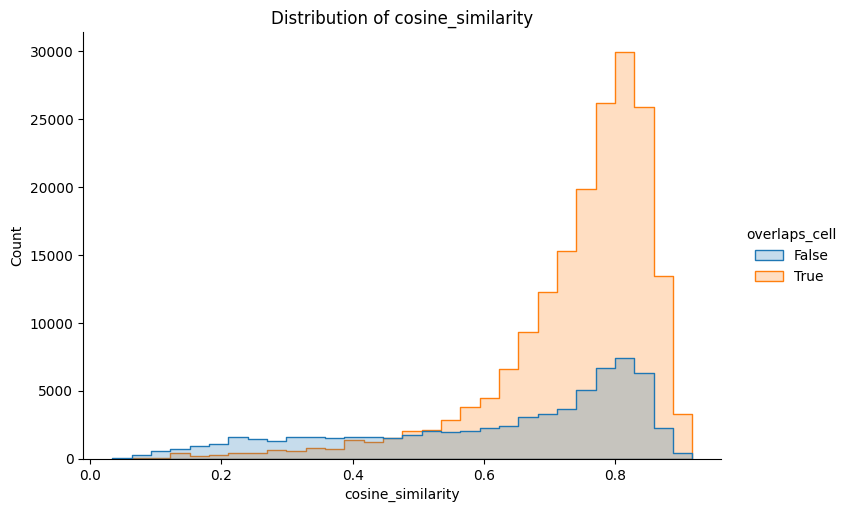

<Figure size 500x500 with 0 Axes>

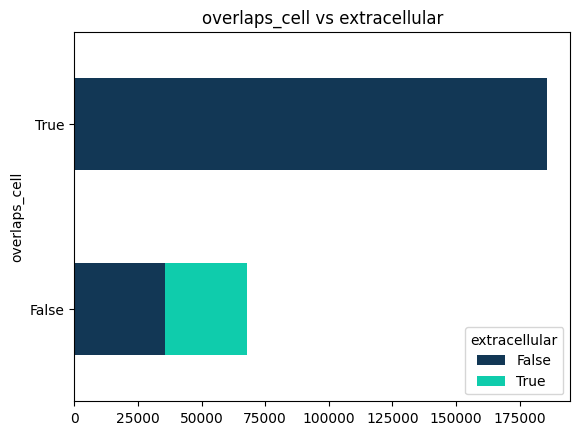

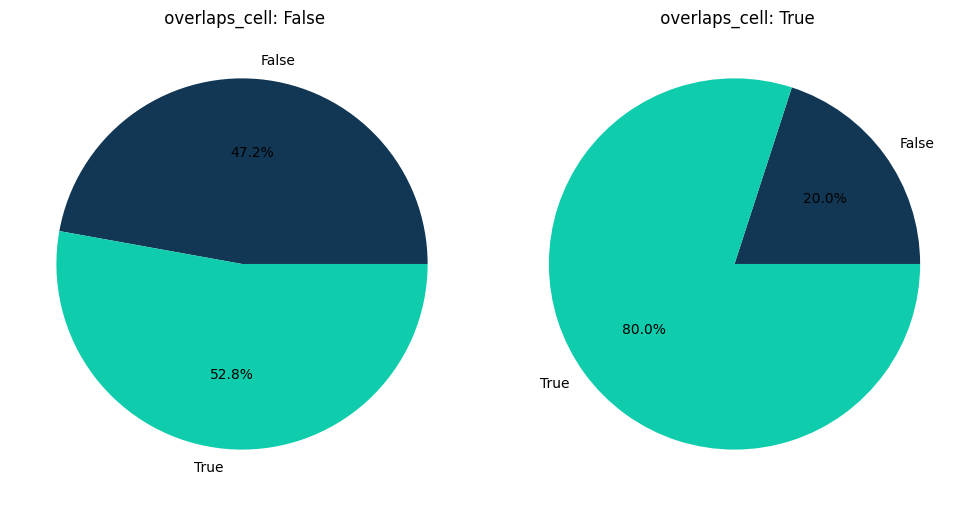

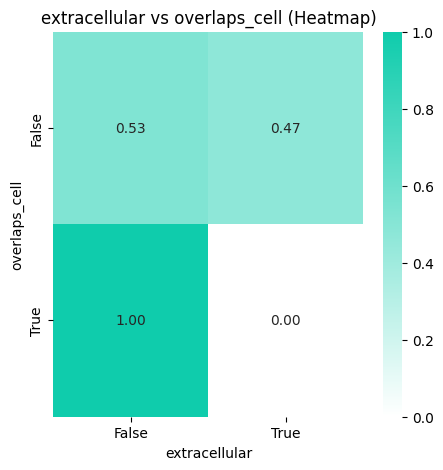

In [59]:
troutpy.pl.histogram(sdata, x="cosine_similarity", hue="overlaps_cell", save=True, figures_path=saving_path)

# we define what we consider extracellular

troutpy.pp.define_extracellular(sdata, layer="transcripts", method="sainsc", copy=False, percentile_threshold=20)

# Define path for saving figures inside function

troutpy.pl.crosstab(
    sdata,
    yvar="extracellular",
    xvar="overlaps_cell",
    normalize=False,
    cmap="troutpy",
    kind="barh",
    stacked=True,
    save=True,
    figures_path=saving_path,
)
troutpy.pl.pie(
    sdata, groupby="match_cell_signature", group_key="overlaps_cell", palette="troutpy", figures_path=saving_path
)
troutpy.pl.crosstab(
    sdata,
    xvar="extracellular",
    yvar="overlaps_cell",
    normalize=True,
    cmap="Aquas",
    kind="heatmap",
    stacked=True,
    save=True,
    figures_path=saving_path,
)

In [71]:
sdata = sd.read_zarr(os.path.join(inpath, "data_processed.zarr"))
# This is an important step to define bins. Square size might be the most important parameter. TBD what is optimal
troutpy.pp.aggregate_extracellular_transcripts(sdata, gene_key="gene", square_size=200)

In [69]:
sdata["segmentation_free_table"].X = sdata["segmentation_free_table"].X.todense()

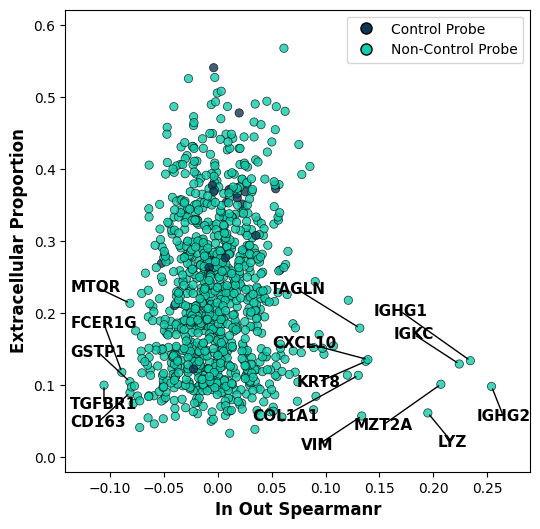

In [72]:
troutpy.tl.in_out_correlation(sdata, n_neighbors=10)  # this is the good one
troutpy.pl.metric_scatter(
    sdata,
    x="in_out_spearmanR",
    y="extracellular_proportion",
    label_top_n_x=10,
    label_bottom_n_x=5,
    figures_path=saving_path,
    save=True,
)

In [63]:
sdata["xrna_metadata"].var

,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized
HDAC5,96,0.064539,False,0.0,0.750000,0.250000,-0.790245,-0.000084,0.468054,9.663336e-07,0.492596,NaN,NaN,0.150000
C1QB,646,1.970990,False,0.0,0.891641,0.108359,0.218755,0.002081,0.016906,9.663336e-07,0.059534,NaN,NaN,0.111111
EGFR,73,-0.209350,False,0.0,0.808219,0.191781,-0.450377,-0.000060,0.477650,9.663336e-07,0.492596,NaN,NaN,0.076923
HSD3B2,76,-0.169076,False,0.0,0.710526,0.289474,-0.990916,-0.000100,0.461677,9.663336e-07,0.492596,NaN,NaN,0.047619
COL21A1,39,-0.836248,False,0.0,0.717949,0.282051,-0.954548,-0.000055,0.479699,9.663336e-07,0.492596,NaN,NaN,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NegPrb8,49,-0.607989,True,0.0,0.877551,0.122449,0.080583,-0.000029,0.490154,9.663336e-07,0.492596,NaN,NaN,0.000000
TPSB2,42,-0.762140,False,0.0,0.761905,0.238095,-0.725707,0.019952,0.000000,9.663336e-07,0.000000,NaN,NaN,0.000000
ADGRG1,46,-0.671168,False,0.0,0.673913,0.326087,-1.162920,0.008646,0.000000,9.663336e-07,0.000000,NaN,NaN,0.166667
RAD51,30,-1.098612,False,0.0,0.866667,0.133333,-0.017055,-0.000020,0.494051,9.663336e-07,0.494051,NaN,NaN,0.000000


Using precomputed segmentation free table


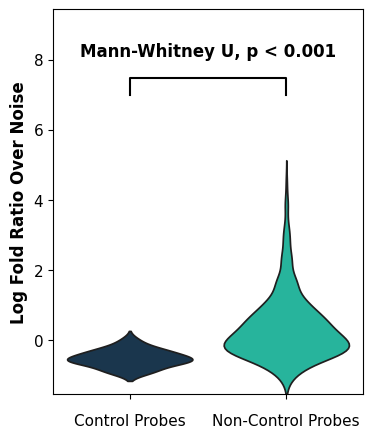

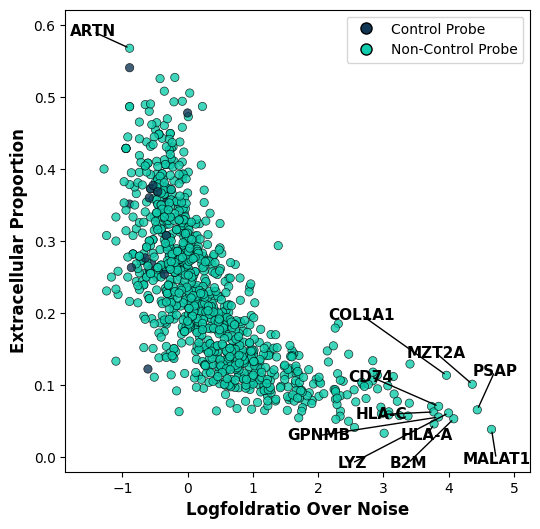

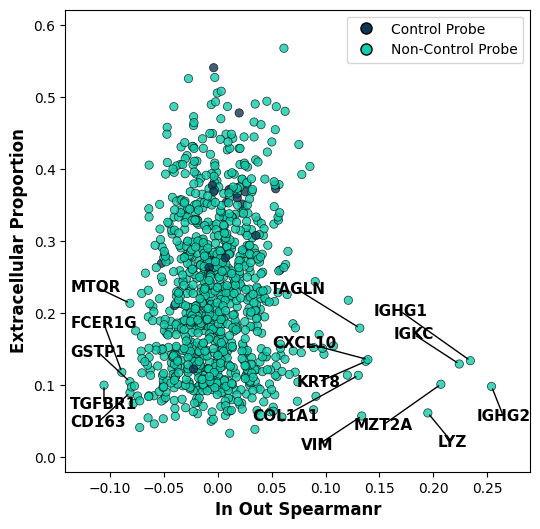

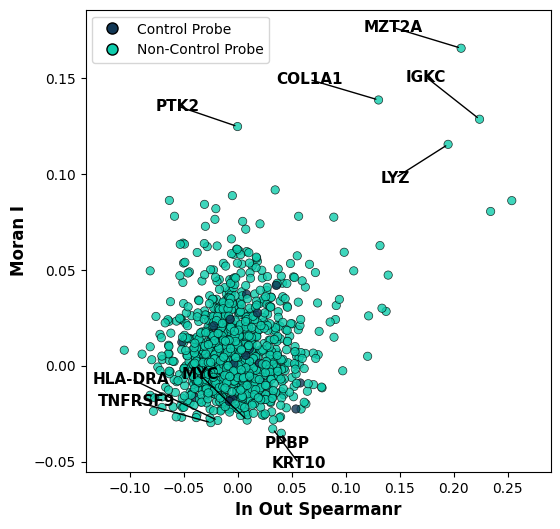

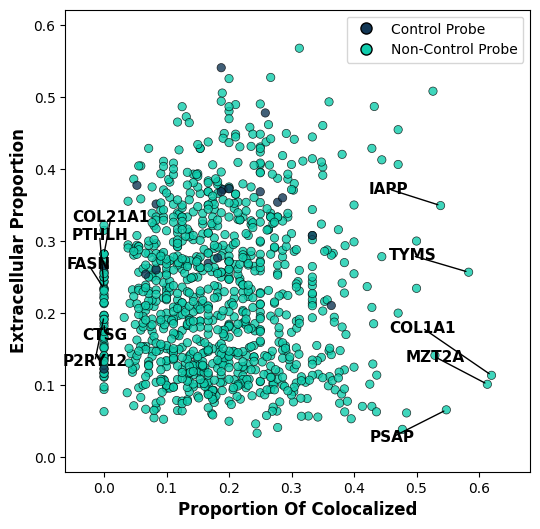

Processing genes: 100%|██████████| 555/555 [00:03<00:00, 183.76it/s]


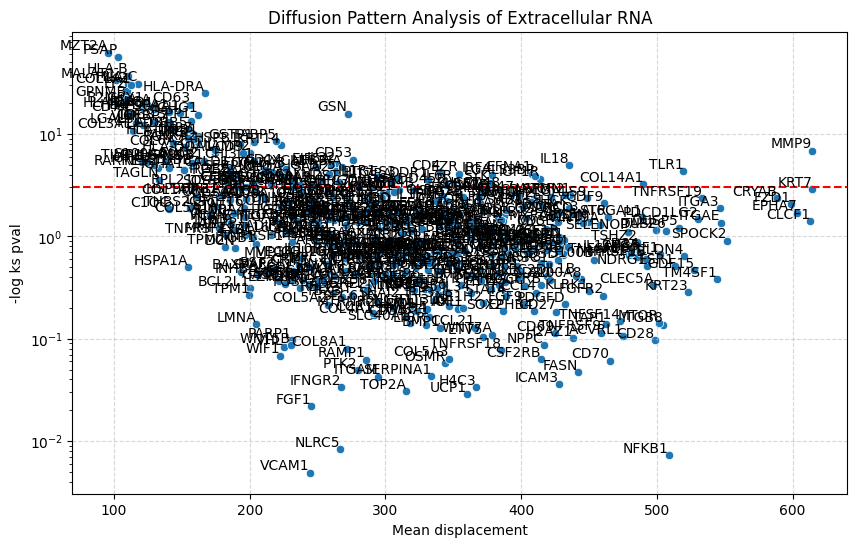

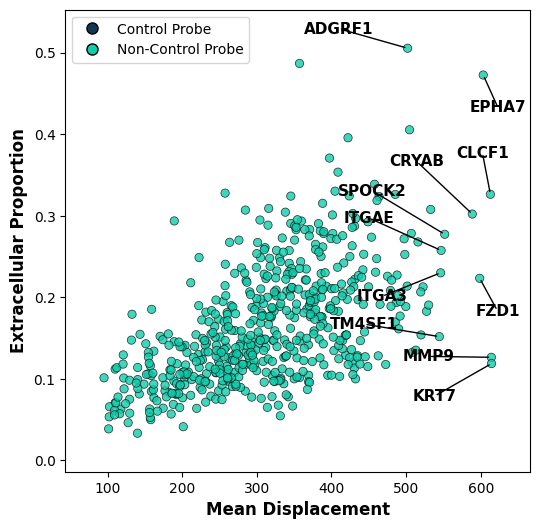

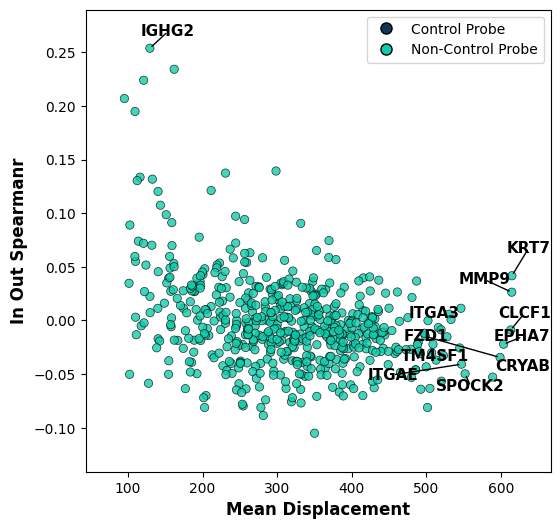

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /media/sergio/Meninges/troutpy/rois/cosmx_hgsoc/data_processed_filtered.zarr). Please   
         see the documentation of `is_self_contained()` to understand the implications of working with SpatialData 
         objects that are not self-contained.                                                                      
INFO     The Zarr backing store has been changed from                                                              
         /media/sergio/Meninges/troutpy/rois/cosmx_hgsoc/data_processed.zarr the new file path:                    
         /media/sergio/Meninges/troutpy/rois/cosmx_hgsoc/data_processed_filtered.zarr                              


In [ ]:
# define spatial statistics
troutpy.tl.quantify_overexpression(sdata, codeword_key="control_probe", control_codewords=[True], gene_key="gene")
troutpy.tl.extracellular_enrichment(sdata, gene_key="gene")
troutpy.tl.spatial_variability(sdata, gene_key="gene", n_neighbors=10, square_size=300)
troutpy.tl.in_out_correlation(sdata, n_neighbors=10)  # this is the good one
troutpy.tl.spatial_colocalization(sdata, threshold_colocalized=1, copy=False)
# plotting
troutpy.pl.logfoldratio_over_noise(sdata, test_method="auto", palette="troutpy", figures_path=saving_path, save=True)
troutpy.pl.metric_scatter(
    sdata,
    x="logfoldratio_over_noise",
    y="extracellular_proportion",
    label_top_n_y=1,
    label_top_n_x=10,
    figures_path=saving_path,
    save=True,
)
troutpy.pl.metric_scatter(
    sdata,
    x="in_out_spearmanR",
    y="extracellular_proportion",
    label_top_n_x=10,
    label_bottom_n_x=5,
    figures_path=saving_path,
    save=True,
)
troutpy.pl.metric_scatter(
    sdata, x="in_out_spearmanR", y="moran_I", label_top_n_y=5, label_bottom_n_y=5, figures_path=saving_path, save=True
)
troutpy.pl.metric_scatter(
    sdata,
    x="proportion_of_colocalized",
    y="extracellular_proportion",
    label_top_n_x=5,
    label_bottom_n_x=5,
    figures_path=saving_path,
    save=True,
)
# save
# sdata.write(os.path.join(inpath,'data_processed.zarr'),overwrite=True)

# Work only of exRNA that is above noise levels

Processing genes: 100%|██████████| 63/63 [00:00<00:00, 9091.70it/s]


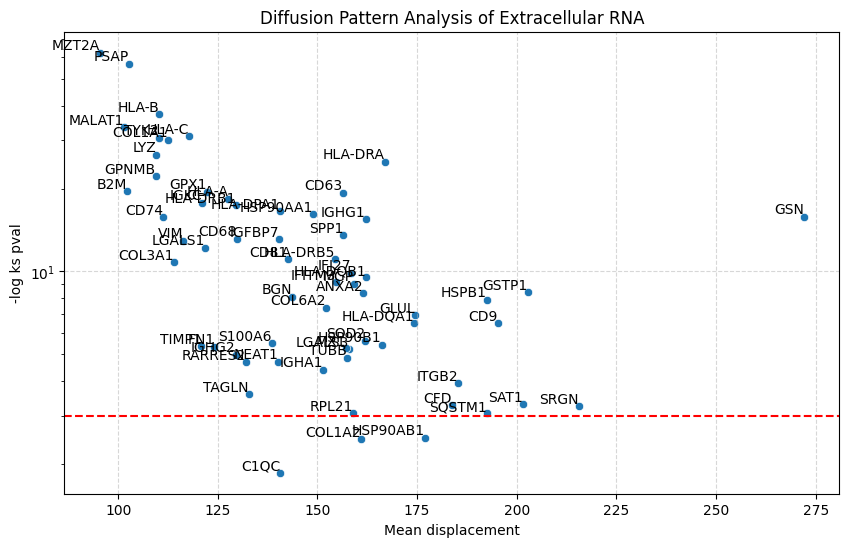

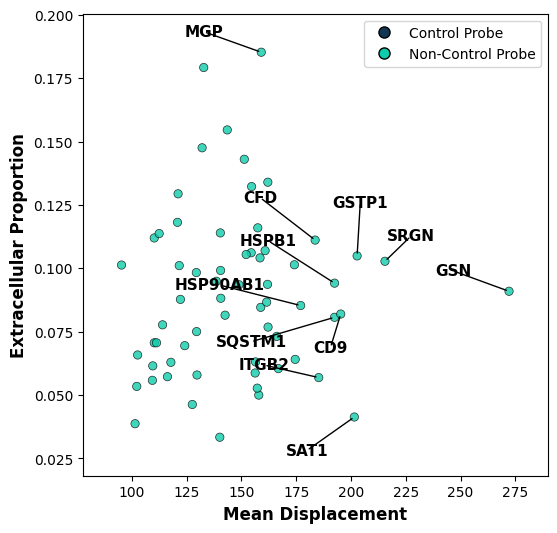

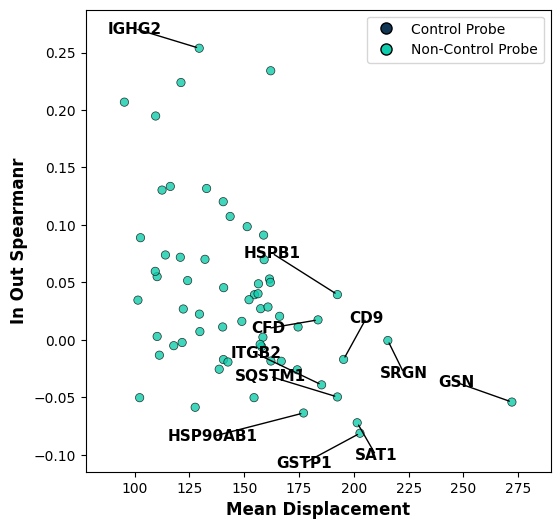

ValueError: Cannot overwrite. The target path of the write operation is in use. Please save the data to a different location. 
Details: the target path either contains, coincides or is contained in the current Zarr store.
Workaround: please see discussion here https://github.com/scverse/spatialdata/discussions/520 .

In [74]:
troutpy.pp.filter_xrna(sdata, min_logfoldratio_over_noise=2, gene_key="gene")
troutpy.tl.compute_source_score(
    sdata, layer="transcripts", gene_key="gene", lambda_decay=0.1, copy=False, celltype_key="leiden"
)
# Work on source identification
troutpy.tl.assess_diffussion(sdata, gene_key="gene", distance_key="distance")
troutpy.pl.diffusion_results(sdata, y_col="-log_ks_pval", y_logscale=True, figures_path=saving_path, save=True)
troutpy.pl.metric_scatter(
    sdata,
    x="mean_displacement",
    y="extracellular_proportion",
    label_top_n_y=1,
    label_top_n_x=10,
    figures_path=saving_path,
    save=True,
)
troutpy.pl.metric_scatter(
    sdata,
    x="mean_displacement",
    y="in_out_spearmanR",
    label_top_n_y=1,
    label_top_n_x=10,
    figures_path=saving_path,
    save=True,
)
sdata.write(os.path.join(inpath, "data_processed_filtered.zarr"), overwrite=True)